<a href="https://colab.research.google.com/github/iamttom/M18/blob/main/iris_m25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# =========================
# 0) Imports e setup
# =========================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Exibir tudo
pd.set_option("display.max_columns", None)


In [ ]:
# =========================
# 1) Carregamento da base
# =========================
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df = df.drop(columns="target")   # retiramos rótulo, pois clustering é não supervisionado
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


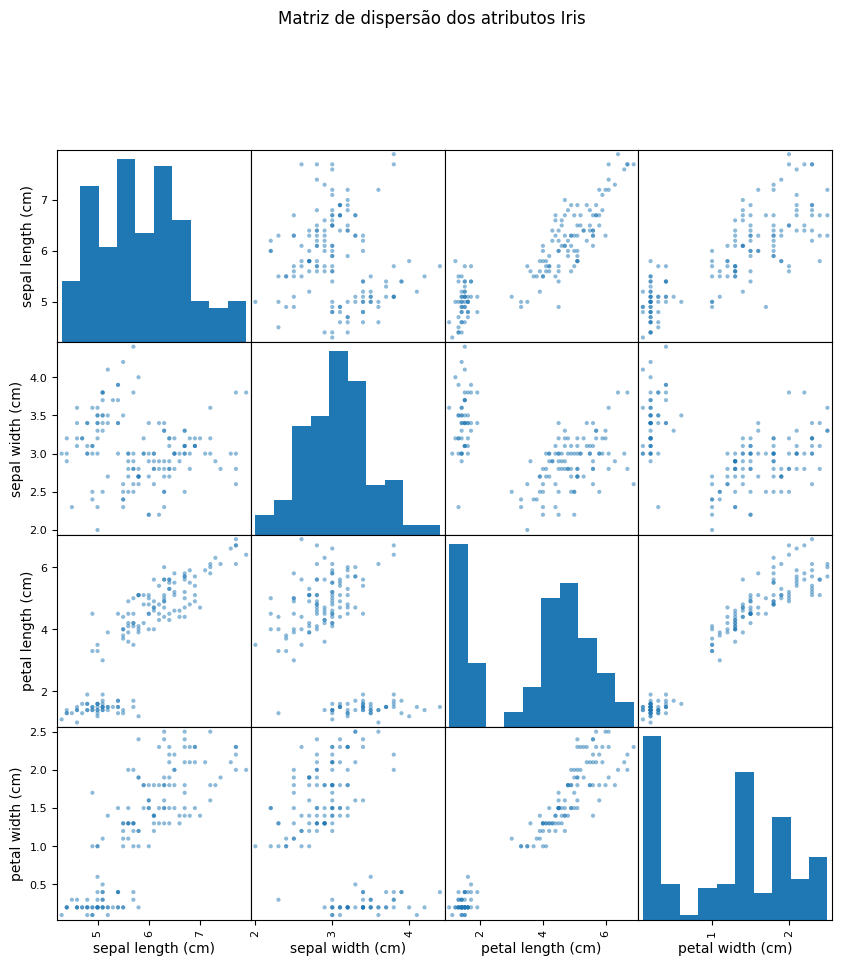

In [ ]:
# =========================
# 1.1) Matriz de dispersão
# =========================
pd.plotting.scatter_matrix(df, figsize=(10,10))
plt.suptitle("Matriz de dispersão dos atributos Iris", y=1.02)
plt.show()


Atributos petal_length e petal_width apresentam boa separação natural em 3 grupos → sinal de que k-means deve funcionar bem.

Já sepal_length e sepal_width não separam tão claramente as espécies.

Pela nuvem de pontos, esperamos 3 clusters, coerente com as 3 espécies originais.

In [ ]:
# =========================
# 2.1) Verificar valores faltantes
# =========================
df.isna().sum()


,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0


In [ ]:
# =========================
# 2.2) Padronização
# =========================
scaler = StandardScaler()
df_std = df.copy()

for col in df.columns:
    df_std[col + "_std"] = scaler.fit_transform(df[[col]])

df_std.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),sepal length (cm)_std,sepal width (cm)_std,petal length (cm)_std,petal width (cm)_std
0,5.1,3.5,1.4,0.2,-0.900681,1.019004,-1.340227,-1.315444
1,4.9,3.0,1.4,0.2,-1.143017,-0.131979,-1.340227,-1.315444
2,4.7,3.2,1.3,0.2,-1.385353,0.328414,-1.397064,-1.315444
3,4.6,3.1,1.5,0.2,-1.506521,0.098217,-1.283389,-1.315444
4,5.0,3.6,1.4,0.2,-1.021849,1.249201,-1.340227,-1.315444


In [ ]:
# =========================
# 2.3) Limpeza
# =========================
df_model = df_std[[c for c in df_std.columns if c.endswith("_std")]].copy()
df_model.head()


,sepal length (cm)_std,sepal width (cm)_std,petal length (cm)_std,petal width (cm)_std
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


In [ ]:
# =========================
# 3.1) Treino com diferentes k
# =========================
wcss = []  # within-cluster sum of squares
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init="auto")
    kmeans.fit(df_model)
    wcss.append(kmeans.inertia_)

wcss


[599.9999999999999,
 222.36170496502294,
 191.02473685317952,
 114.35407164049774,
 91.04766991109521,
 81.5507569957175,
 80.77773933734281,
 64.42674849482268,
 55.7069004793369,
 51.121095396505524]

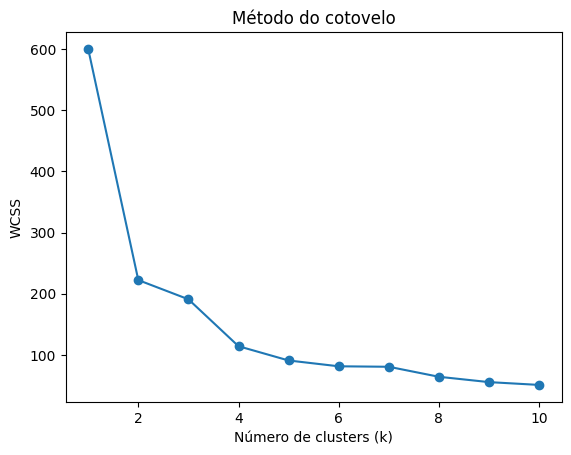

In [ ]:
# =========================
# 3.2) Elbow method
# =========================
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("WCSS")
plt.title("Método do cotovelo")
plt.show()


O gráfico mostra uma queda brusca até k=3, depois estabiliza. Portanto, o número de clusters ideal é 3.

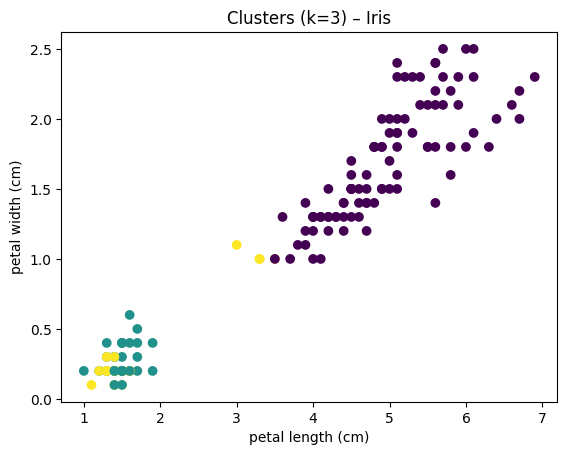

In [ ]:
# =========================
# 3.3) KMeans final com k=3
# =========================
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init="auto")
df["cluster"] = kmeans_final.fit_predict(df_model)

# Gráfico 2D simples (petal_length x petal_width, os mais separáveis)
plt.scatter(df["petal length (cm)"], df["petal width (cm)"], c=df["cluster"], cmap="viridis")
plt.xlabel("petal length (cm)")
plt.ylabel("petal width (cm)")
plt.title("Clusters (k=3) – Iris")
plt.show()

Os clusters coincidem com os 3 grupos naturais das flores (setosa, versicolor, virginica). O algoritmo agrupou corretamente apenas com base nas medidas, sem usar rótulos.

In [ ]:
# =========================
# 4) Predição nova flor
# =========================
nova = pd.DataFrame([{
    "sepal length (cm)": 5.1,
    "sepal width (cm)": 3.5,
    "petal length (cm)": 1.4,
    "petal width (cm)": 0.2
}])

# Padronizar igual ao treino
nova_std = scaler.fit(df[["sepal length (cm)","sepal width (cm)","petal length (cm)","petal width (cm)"]])  # treina scaler
nova_scaled = nova_std.transform(nova)

cluster_pred = kmeans_final.predict(nova_scaled)[0]
print("A nova flor foi alocada no cluster:", cluster_pred)

A nova flor foi alocada no cluster: 1


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(
